In [19]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

In [20]:
df = pd.read_csv(
    "data/nifty_cleaned.csv"
)

df["Date"] = pd.to_datetime(df["Date"])

df.head()

,Date,Adj Close,Close,High,Low,Open,Volume,Daily_Return_%,MA_50,MA_200,Year
0,2016-06-01,8179.950195,8179.950195,8215.349609,8171.049805,8179.200195,194400.0,NaN,NaN,NaN,2016
1,2016-06-02,8218.950195,8218.950195,8229.500000,8154.750000,8156.899902,181700.0,0.476776,NaN,NaN,2016
2,2016-06-03,8220.799805,8220.799805,8262.000000,8209.849609,8246.200195,379000.0,0.022504,NaN,NaN,2016
3,2016-06-06,8201.049805,8201.049805,8234.700195,8186.049805,8228.750000,171600.0,-0.240244,NaN,NaN,2016
4,2016-06-07,8266.450195,8266.450195,8294.950195,8216.400391,8235.549805,241900.0,0.797464,NaN,NaN,2016


In [21]:
df["Weekday"] = df["Date"].dt.day_name()

df["Abs_Return"] = (
    df["Daily_Return_%"]
    .abs()
)

In [22]:
# 1.Hypothesis 1:
# Mean Daily Return ≠ 0
# 2.Null Hypothesis
# H0:
# Mean return = 0
# 3.Alternative Hypothesis
# H1:
# Mean return ≠ 0

In [23]:
# One-Sample T-Test
returns = (
    df["Daily_Return_%"]
    .dropna()
)

t_stat, p_value = stats.ttest_1samp(
    returns,
    popmean=0
)

print("T Statistic:", t_stat)
print("P-value:", p_value)


T Statistic: 2.3630009439217305
P-value: 0.018204358383803833


In [24]:
ci = stats.t.interval(0.95, len(returns)-1, loc=returns.mean(), scale=stats.sem(returns))
print("Mean daily return:", returns.mean())
print("95% CI:", ci)

Mean daily return: 0.04839503838683634
95% CI: (np.float64(0.00823473762247695), np.float64(0.08855533915119573))


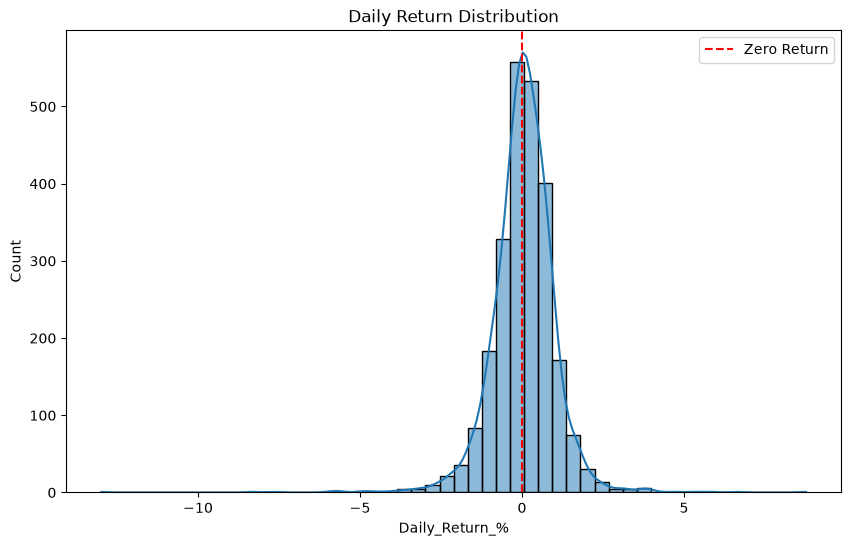

In [25]:
# Return Distribution
plt.figure(figsize=(10,6))

sns.histplot(
    returns,
    bins=50,
    kde=True
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero Return"
)

plt.title(
    "Daily Return Distribution"
)

plt.legend()

plt.show()

In [26]:
# Interpretation
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Mean return differs significantly from zero.")
else:
    print("Fail to reject H0")
    print("No significant evidence that mean return differs from zero.")

Reject H0
Mean return differs significantly from zero.


In [27]:
# Hypothesis 2
# COVID Volatility vs Normal Years

In [28]:
# Create Volatility Groups
covid_returns = (
    df[
        df["Year"] == 2020
    ]["Daily_Return_%"]
    .dropna()
)

normal_returns = (
    df[
        (df["Year"] >= 2017)
        &
        (df["Year"] <= 2019)
    ]["Daily_Return_%"]
    .dropna()
)

In [29]:
# Levene Test
levene_stat, levene_p = stats.levene(
    covid_returns,
    normal_returns
)

print("Levene Statistic:", levene_stat)
print("P-value:", levene_p)


Levene Statistic: 91.63878320669023
P-value: 8.14562327496182e-21


In [30]:
# Welch T-Test
t_stat2, p_value2 = stats.ttest_ind(
    covid_returns.abs(),
    normal_returns.abs(),
    equal_var=False
)

print("T Statistic:", t_stat2)
print("P-value:", p_value2)


T Statistic: 6.556884088154838
P-value: 2.82382525676238e-10


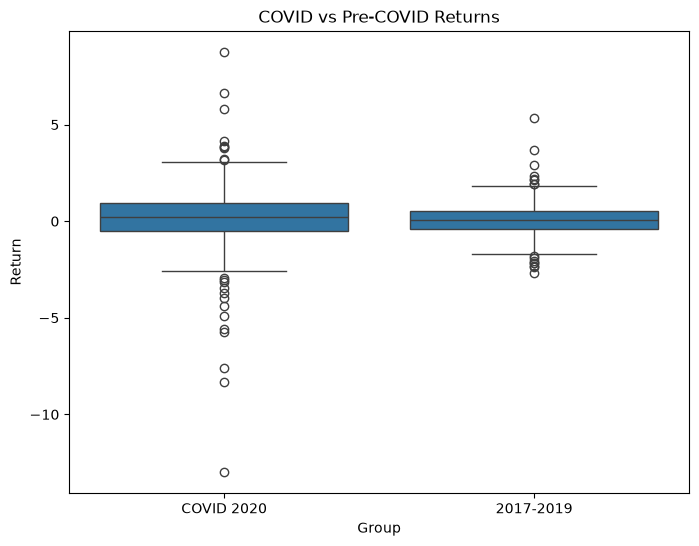

In [31]:
# Boxplot
compare_df = pd.DataFrame(
    {
        "Return":
        pd.concat(
            [
                covid_returns,
                normal_returns
            ]
        ),

        "Group":
        (
            ["COVID 2020"] * len(covid_returns)
            +
            ["2017-2019"] * len(normal_returns)
        )
    }
)

plt.figure(figsize=(8,6))

sns.boxplot(
    x="Group",
    y="Return",
    data=compare_df
)

plt.title(
    "COVID vs Pre-COVID Returns"
)

plt.show()

In [32]:
# 1. Hypothesis 3:
# Day-of-Week Effect
# 2. Null:
# Average returns are equal across weekdays.
# 3. Alternative:
# At least one weekday has a different average return.

In [33]:
# Prepare Groups
weekday_groups = []

for day in [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday"
]:
    weekday_groups.append(
        df[
            df["Weekday"] == day
        ]["Daily_Return_%"].dropna()
    )


In [34]:
# ANOVA Test
f_stat, p_value3 = stats.f_oneway(
    *weekday_groups
)

print("F Statistic:", f_stat)
print("P-value:", p_value3)

F Statistic: 2.3843154388910226
P-value: 0.04928120549738427


In [35]:

from statsmodels.stats.multicomp import pairwise_tukeyhsd
tmp = df.dropna(subset=["Daily_Return_%"])
print(pairwise_tukeyhsd(tmp["Daily_Return_%"], tmp["Weekday"]))

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1    group2  meandiff p-adj   lower  upper  reject
--------------------------------------------------------
  Friday    Monday   -0.064  0.923 -0.2493 0.1214  False
  Friday  Saturday  -0.1405    1.0 -3.0507 2.7697  False
  Friday  Thursday   -0.018 0.9998 -0.2027 0.1666  False
  Friday   Tuesday   0.1158 0.4751 -0.0691 0.3007  False
  Friday Wednesday   0.0636 0.9243 -0.1213 0.2485  False
  Monday  Saturday  -0.0765    1.0 -2.9867 2.8337  False
  Monday  Thursday   0.0459 0.9807 -0.1385 0.2304  False
  Monday   Tuesday   0.1798 0.0618  -0.005 0.3645  False
  Monday Wednesday   0.1275 0.3604 -0.0572 0.3122  False
Saturday  Thursday   0.1224    1.0 -2.7877 3.0326  False
Saturday   Tuesday   0.2563 0.9999 -2.6539 3.1664  False
Saturday Wednesday    0.204    1.0 -2.7061 3.1142  False
Thursday   Tuesday   0.1338 0.3011 -0.0502 0.3178  False
Thursday Wednesday   0.0816 0.8041 -0.1024 0.2656  False
 Tuesday Wednesday  -0.0522 0.9

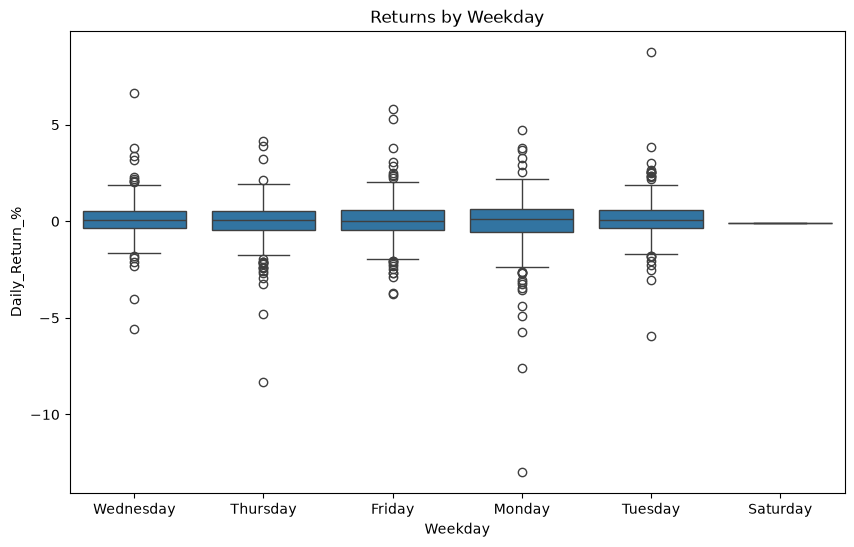

In [36]:
# Weekday Visualization
plt.figure(figsize=(10,6))

sns.boxplot(
    x="Weekday",
    y="Daily_Return_%",
    data=df
)

plt.title(
    "Returns by Weekday"
)

plt.show()

In [37]:
# Hypothesis 4
# Volume vs Absolute Return
# From Week 1:
# Correlation ≈ very weak
# Yahoo index volume may be unreliable

In [38]:
sub = df.dropna(subset=["Volume", "Abs_Return"])
corr, p_value4 = stats.pearsonr(sub["Volume"], sub["Abs_Return"])
print("Correlation:", corr)
print("P-value:", p_value4)
print("n =", len(sub))

Correlation: 0.37079772150218787
P-value: 7.640875213757796e-81
n = 2454


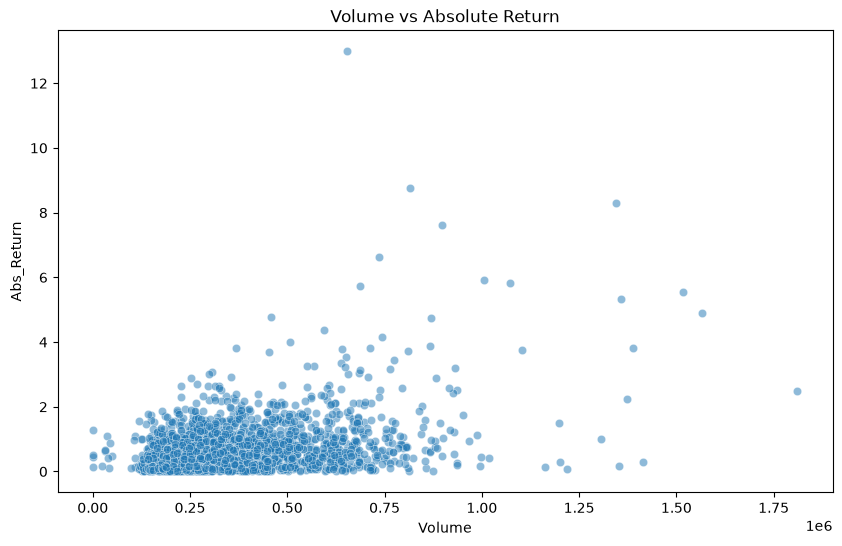

In [39]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x="Volume",
    y="Abs_Return",
    data = sub,
    alpha=0.5
)

plt.title(
    "Volume vs Absolute Return"
)

plt.show()

In [40]:
print("WEEK 3 SUMMARY")

print("- Tested whether mean daily return differs from zero")
print("- Compared COVID and pre-COVID market behavior")
print("- Evaluated return variance using Levene's test")
print("- Applied Welch's t-test for unequal variances")
print("- Investigated weekday effects using ANOVA")
print("- Explored volume and absolute return relationship")
print("- Interpreted statistical significance using p-values")

WEEK 3 SUMMARY
- Tested whether mean daily return differs from zero
- Compared COVID and pre-COVID market behavior
- Evaluated return variance using Levene's test
- Applied Welch's t-test for unequal variances
- Investigated weekday effects using ANOVA
- Explored volume and absolute return relationship
- Interpreted statistical significance using p-values
